# **Session 6: Contextualized Language Models**


## Text Classification using ELMo (Embeddings for Language Models)


In [1]:
import pandas as pd
import numpy as np
import tensorflow_hub as hub


import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, BatchNormalization, Lambda

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

/Users/fangsiyu/dev-env/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):
/Users/fangsiyu/dev-env/lib/python3.13/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [2]:
#@title 1. Load and Prepare Dataset

df = pd.read_csv('imdb_5000.csv')
display(df.head())
print(df['sentiment'].value_counts())



,review,sentiment
0,I got the DVD very cheap and I'm a total Drewb...,negative
1,I liked this comedy so much. Will Smith does n...,positive
2,What a piece of junk this movie was. The premi...,negative
3,"I am a big fan of the movie, but not for the u...",positive
4,Im going to keep this fairly brief as to not s...,positive


sentiment
negative    2500
positive    2500
Name: count, dtype: int64


In [3]:

# Encode sentiment: positive -> 1, negative -> 0
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})
df.drop(columns=['sentiment'], inplace=True)

# For demonstration purposes, let's use a subset for faster training
# Remove this line if you want to use the full dataset
df = df.sample(n=5000, random_state=42).reset_index(drop=True)

print(f"Using {len(df)} samples for training")

# Split the data
# X = df['review'].values
# y = df['label'].values
X = df['review'].to_numpy(dtype=object)
y = df['label'].to_numpy(dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

Using 5000 samples for training
Training samples: 4000
Testing samples: 1000


In [4]:
import tensorflow_hub as hub

# ELMo URL from TensorFlow Hub
elmo_url = "https://tfhub.dev/google/elmo/3"

# Load ELMo as a hub module
elmo = hub.load(elmo_url)

In [5]:
sentences = ["I ate an apple", 
             "I bought an apple"]
embeddings = elmo.signatures['default'](tf.constant(sentences))['elmo']
print(embeddings.shape)

(2, 4, 1024)


In [6]:
embeddings[0][3]

<tf.Tensor: shape=(1024,), dtype=float32, numpy=
array([ 0.707569  , -0.3842671 ,  0.8141682 , ...,  0.14826332,
        0.4691129 ,  0.611744  ], shape=(1024,), dtype=float32)>

In [7]:
embeddings[1][3]

<tf.Tensor: shape=(1024,), dtype=float32, numpy=
array([ 0.48918712, -0.38563943,  0.5468861 , ...,  0.14826332,
        0.4691129 ,  0.611744  ], shape=(1024,), dtype=float32)>

In [8]:
# Create ELMo Embedding Function

def embed_elmo(texts):
    """
    Convert texts to ELMo embeddings
    Args:
        texts: List or array of text strings
    Returns:
        ELMo embeddings (1024-dimensional vectors)
    """
    # ELMo expects a list of strings
    embeddings = elmo.signatures['default'](
        tf.constant(texts.tolist() if isinstance(texts, np.ndarray) else texts)
    )['elmo']


    # Average the word embeddings to get sentence-level representation
    # This gives us a fixed-size 1024-dimensional vector per sentence
    sentence_embeddings = tf.reduce_mean(embeddings, axis=1)

    return sentence_embeddings


In [9]:

# Generate ELMo embeddings in memory-safe batches

def generate_embeddings_batch(texts, batch_size=4, max_words=150):
    """
    Generate ELMo embeddings with smaller batches
    and a maximum number of words per review.
    """
    texts = np.asarray(texts, dtype=str)

    # Truncate long reviews before passing them to ELMo
    texts = np.array([
        " ".join(text.split()[:max_words])
        for text in texts
    ])

    embeddings = []

    for start_idx in range(0, len(texts), batch_size):
        end_idx = min(start_idx + batch_size, len(texts))
        batch = texts[start_idx:end_idx]

        batch_embeddings = embed_elmo(batch)
        embeddings.append(batch_embeddings.numpy())

        if end_idx % 100 < batch_size or end_idx == len(texts):
            print(f"Processed {end_idx}/{len(texts)} samples...")

    return np.vstack(embeddings)


# Generate embeddings
X_train_elmo = generate_embeddings_batch(
    X_train, batch_size=4, max_words=150
)

X_test_elmo = generate_embeddings_batch(
    X_test, batch_size=4, max_words=150
)

print("Training embeddings:", X_train_elmo.shape)
print("Test embeddings:", X_test_elmo.shape)


Processed 100/4000 samples...
Processed 200/4000 samples...
Processed 300/4000 samples...
Processed 400/4000 samples...
Processed 500/4000 samples...
Processed 600/4000 samples...
Processed 700/4000 samples...
Processed 800/4000 samples...
Processed 900/4000 samples...
Processed 1000/4000 samples...
Processed 1100/4000 samples...
Processed 1200/4000 samples...
Processed 1300/4000 samples...
Processed 1400/4000 samples...
Processed 1500/4000 samples...
Processed 1600/4000 samples...
Processed 1700/4000 samples...
Processed 1800/4000 samples...
Processed 1900/4000 samples...
Processed 2000/4000 samples...
Processed 2100/4000 samples...
Processed 2200/4000 samples...
Processed 2300/4000 samples...
Processed 2400/4000 samples...
Processed 2500/4000 samples...
Processed 2600/4000 samples...
Processed 2700/4000 samples...
Processed 2800/4000 samples...
Processed 2900/4000 samples...
Processed 3000/4000 samples...
Processed 3100/4000 samples...
Processed 3200/4000 samples...
Processed 3300/40

In [10]:
input_dim=1024

model = Sequential([
    Input(shape=(input_dim,), name='elmo_input'),

    # Dense(256, activation='relu', name='dense_1'),
    Dense(128, activation='relu', name='dense_2'),
    Dense(64, activation='relu', name='dense_3'),
    Dense(32, activation='relu', name='dense_4'),
    Dense(1, activation='sigmoid', name='output')
], name='sentiment_classifier')


# Compile the Model
model.compile(
    optimizer="adam",
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train the Model
es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=3)
history = model.fit(
    X_train_elmo,
    y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    callbacks=[es],
    verbose=1
)


Model: "sentiment_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 141,569 (553.00 KB)

 Trainable params: 141,569 (553.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7084 - loss: 0.5664 - val_accuracy: 0.7713 - val_loss: 0.4900
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 887us/step - accuracy: 0.7903 - loss: 0.4518 - val_accuracy: 0.7462 - val_loss: 0.5255
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 831us/step - accuracy: 0.8003 - loss: 0.4377 - val_accuracy: 0.7950 - val_loss: 0.4484
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 864us/step - accuracy: 0.8206 - loss: 0.3969 - val_accuracy: 0.8000 - val_loss: 0.4096
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step - accuracy: 0.8250 - loss: 0.3922 - val_accuracy: 0.7688 - val_loss: 0.4877
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 826us/step - accuracy: 0.8322 - loss: 0.3826 - val_accuracy: 0.7725 - val_loss: 0.4828
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 823us/step - accuracy: 0.8419 - loss: 0.3685 - val_accuracy: 0.8100 - val_loss: 0.4017
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8475 - loss: 0.3505 - val_

In [11]:

from sklearn.metrics import classification_report, confusion_matrix

# Evaluate on test set
test_loss, test_accuracy = model.evaluate(X_test_elmo, y_test, verbose=0)
print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# Make Predictions and Detailed Analysis

# Make predictions
y_pred_prob = model.predict(X_test_elmo, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

# Classification report
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

# Confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
cm


Test Accuracy: 0.7950
Test Loss: 0.4605
              precision    recall  f1-score   support

    Negative       0.84      0.73      0.78       500
    Positive       0.76      0.86      0.81       500

    accuracy                           0.80      1000
   macro avg       0.80      0.79      0.79      1000
weighted avg       0.80      0.80      0.79      1000


Confusion Matrix:


array([[364, 136],
       [ 69, 431]])

In [12]:
# Test on Sample Reviews

sample_reviews = np.array([
    "This movie was absolutely fantastic! The acting was superb and the plot kept me engaged throughout.",
    "Terrible waste of time. The story made no sense and the acting was awful.",
    "It was okay, not great but not terrible either.",
    "One of the best films I've ever seen! Highly recommended!",
    "Boring and predictable. I fell asleep halfway through.",
    "I bought a car that is very predictible"
])

sample_embeddings = generate_embeddings_batch(sample_reviews, batch_size=5)
predictions = model.predict(sample_embeddings, verbose=0)


for i, review in enumerate(sample_reviews):
    sentiment = "Positive" if predictions[i][0] > 0.5 else "Negative"
    confidence = predictions[i][0] if predictions[i][0] > 0.5 else 1 - predictions[i][0]
    print(f"\n{i+1}. Review: {review[:80]}...")
    print(f"   Prediction: {sentiment} (confidence: {confidence:.2%})")

Processed 6/6 samples...

1. Review: This movie was absolutely fantastic! The acting was superb and the plot kept me ...
   Prediction: Positive (confidence: 99.21%)

2. Review: Terrible waste of time. The story made no sense and the acting was awful....
   Prediction: Negative (confidence: 99.77%)

3. Review: It was okay, not great but not terrible either....
   Prediction: Negative (confidence: 74.14%)

4. Review: One of the best films I've ever seen! Highly recommended!...
   Prediction: Positive (confidence: 99.63%)

5. Review: Boring and predictable. I fell asleep halfway through....
   Prediction: Negative (confidence: 97.71%)

6. Review: I bought a car that is very predictible...
   Prediction: Positive (confidence: 96.34%)




---


## Seq2Seq Translation and Attention Visualization

### 1- Load the pretrained French → English model

In [15]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import MarianMTModel, MarianTokenizer

model_name = "Helsinki-NLP/opus-mt-fr-en"

tokenizer = MarianTokenizer.from_pretrained(model_name)
model = MarianMTModel.from_pretrained(
    model_name,
    attn_implementation="eager"
)

model.eval()

print("Model loaded successfully!")

ImportError: 
MarianTokenizer requires the SentencePiece library but it was not found in your environment. Check out the instructions on the
installation page of its repo: https://github.com/google/sentencepiece#installation and follow the ones
that match your environment. Please note that you may need to restart your runtime after installation.


### 2- Translate a sentence

In [ ]:
source_text = "Je suis étudiant." # Le chat dort

inputs = tokenizer(
    source_text,
    return_tensors="pt",
    truncation=True
)

with torch.no_grad():
    generated_ids = model.generate(
        **inputs,
        max_new_tokens=30,
        num_beams=1
    )

translation = tokenizer.decode(
    generated_ids[0],
    skip_special_tokens=True
)

print("Source:", source_text)
print("Translation:", translation)


[transformers] Both `max_new_tokens` (=30) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Source: Je suis étudiant.
Translation: I'm a student.


### 3- Extract cross-attention

In [ ]:

# Feed the generated sequence into the decoder.
# The decoder predicts the next token at each position.

decoder_input_ids = generated_ids[:, :-1]

with torch.no_grad():
    outputs = model(
        **inputs,
        decoder_input_ids=decoder_input_ids,
        output_attentions=True,
        return_dict=True
    )

# Cross-attention: one tensor per decoder layer
print("Number of decoder layers:",
      len(outputs.cross_attentions))

# Select the last decoder layer
attention = outputs.cross_attentions[-1]

print("Attention shape:", attention.shape)

# Average across attention heads
attention_matrix = attention[0].mean(dim=0).cpu().numpy()

source_tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0].tolist()
)

target_tokens = tokenizer.convert_ids_to_tokens(
    generated_ids[0, 1:].tolist()
)

print("Source tokens:", source_tokens)
print("Target tokens:", target_tokens)


Number of decoder layers: 6
Attention shape: torch.Size([1, 8, 7, 5])
Source tokens: ['▁Je', '▁suis', '▁étudiant', '.', '</s>']
Target tokens: ['▁I', "'", 'm', '▁a', '▁student', '.', '</s>']


### 4- Visualize the attention matrix

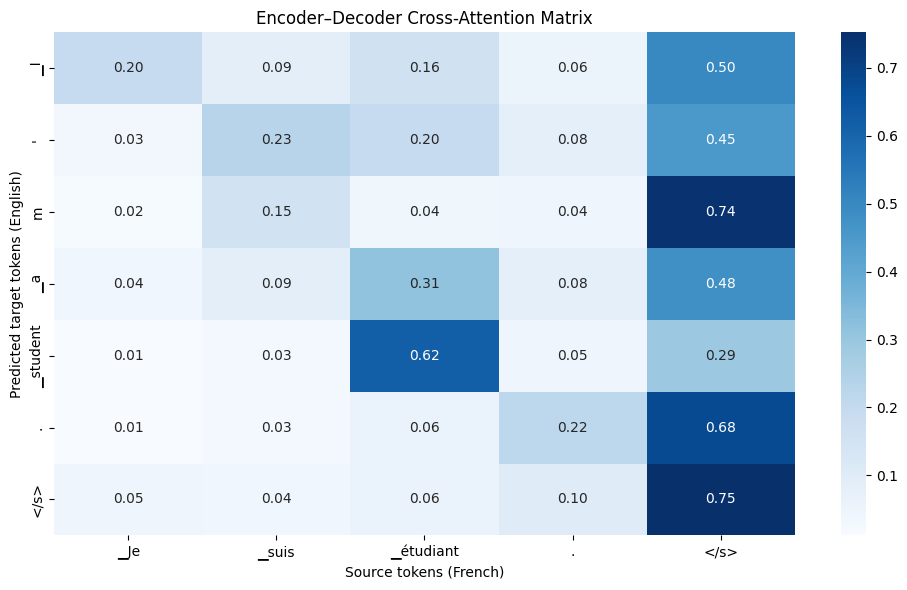

In [ ]:

plt.figure(figsize=(10, 6))

sns.heatmap(
    attention_matrix,
    xticklabels=source_tokens,
    yticklabels=target_tokens,
    cmap="Blues",
    annot=True,
    fmt=".2f"
)

plt.xlabel("Source tokens (French)")
plt.ylabel("Predicted target tokens (English)")
plt.title("Encoder–Decoder Cross-Attention Matrix")

plt.tight_layout()
plt.show()
